# MiniHEP: a masked four-vector transformer on ATLAS Open Data WW events

Self-supervised exercise: each event is a sequence of up to five object tokens (two leptons, two stored jets, missing transverse momentum). We train a small transformer encoder to reconstruct the four numbers of a hidden token from the visible objects. **This is a teaching exercise, not a physics measurement.** The signal/background `label` is in the file but must **not** be used to pretrain the model.

Run all cells top to bottom with a CPU-only kernel.

In [1]:
# 1. Setup -------------------------------------------------------------
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")

import sys
import pathlib

# Make the package importable wherever this notebook is run from: find the
# directory that contains dataWW_d1.root (the course checkout root).
_cwd = pathlib.Path.cwd().resolve()
_root = next((d for d in [_cwd, *_cwd.parents] if (d / "dataWW_d1.root").exists()), _cwd)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))
print("course root:", _root)

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch

%matplotlib inline
torch.set_num_threads(1)  # one CPU thread
print("torch", torch.__version__, "| threads", torch.get_num_threads())

course root: /data/gwatts


torch 2.13.0 | threads 1


In [2]:
# 2. Load the data -----------------------------------------------------
from minihep_student import data as d

ev = d.load_events(max_events=6000, seed=42)   # at most 6000 events, lep_n == 2
print("events:", ev.n_events)
print("fourvec   ", ev.fourvec.shape,   " (events, slots, components) in GeV")
print("token_types", ev.token_types.shape)
print("valid     ", ev.valid.shape)
print("token types present:", sorted(set(ev.token_types.ravel().tolist())))
print()
print(d.format_event(ev, 0))

events: 6000
fourvec    (6000, 5, 4)  (events, slots, components) in GeV
token_types (6000, 5)
valid      (6000, 5)
token types present: [0, 1, 2, 3, 4, 5, 6]

event #0: file_row=508006 run=284500 eventNumber=574690 channel=345323 label=1 mcWeight=2.0068e-06
  slot 0   e- : px=  -13.492 py=  -28.385 pz=  -47.679 E=   57.105 GeV
  slot 1   e+ : px=  -14.418 py=   14.925 pz=  -48.044 E=   52.333 GeV
  slot 2  jet : px=   23.121 py=  -41.677 pz=  -49.729 E=   69.101 GeV
  slot 3  PAD (padding): px=    0.000 py=    0.000 pz=    0.000 E=    0.000 GeV
  slot 4  met : px=   11.166 py=   81.963 pz=    0.000 E=   82.720 GeV


## 3. Split and scale

A reproducible, disjoint 70/15/15 split is made by event index. A feature scaler is fitted using **only the valid tokens of the training events**: `asinh(component / 50 GeV)` then per-component standardisation. The same statistics transform all splits; padded tokens are reset to zero. Event identity, labels and MC weights are metadata and never token features.

In [3]:
# 3. Split and scale --------------------------------------------------
from minihep_student import scale as s

train, val, test = d.split_events(ev)
print(f"split sizes: train {train.n_events}  val {val.n_events}  test {test.n_events}")

ids = [set(x.event_index.tolist()) for x in (train, val, test)]
overlap = (ids[0] & ids[1]) | (ids[0] & ids[2]) | (ids[1] & ids[2])
print("event-id overlap across splits:", len(overlap))
assert len(overlap) == 0

scaler = s.fit_scaler_for_split(train)
print("scaler.mean:", scaler.mean.round(3))
print("scaler.std :", scaler.std.round(3))

split sizes: train 4200  val 900  test 900
event-id overlap across splits: 0
scaler.mean: [6.000e-03 1.000e-03 8.000e-03 1.193e+00]
scaler.std : [0.737 0.737 1.125 0.677]


In [4]:
# 4. Build the model ----------------------------------------------
from minihep_student.model import MiniHEP, count_parameters

model = MiniHEP()
n_params = count_parameters(model)
print(f"MiniHEP trainable parameters: {n_params:,}")

MiniHEP trainable parameters: 17,636


/data/gwatts/minihep_student/model.py:53: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)


## 5. Mask and train

About 25% of each event's **valid** tokens are masked per pass (always at least one hidden and one visible). A masked token keeps its type but loses its four continuous values; padding is never masked or scored. Loss = mean squared error over the four scaled components of the hidden tokens only.

Training: AdamW, batch 64, lr 1e-3, 4 epochs, one CPU thread. Training masks are resampled each pass; a fixed seeded mask sequence is reused for validation so epochs are comparable.

In [5]:
# 5. Train -------------------------------------------------------------
from minihep_student import train as trn

Xtr, TTtr, Vtr = trn.to_tensors(train, scaler)
Xva, TTva, Vva = trn.to_tensors(val, scaler)
Xte, TTte, Vte = trn.to_tensors(test, scaler)

train_hist, val_hist = trn.train_model(
    model, Xtr, TTtr, Vtr, Xva, TTva, Vva,
    epochs=4, batch_size=64, lr=1e-3, seed=0,
)
print("train loss by epoch:", [round(h, 4) for h in train_hist])
print("val   loss by epoch:", [round(h, 4) for h in val_hist])

train loss by epoch: [1.312, 0.9219, 0.8229, 0.8119]
val   loss by epoch: [0.8062, 0.7289, 0.6955, 0.6747]


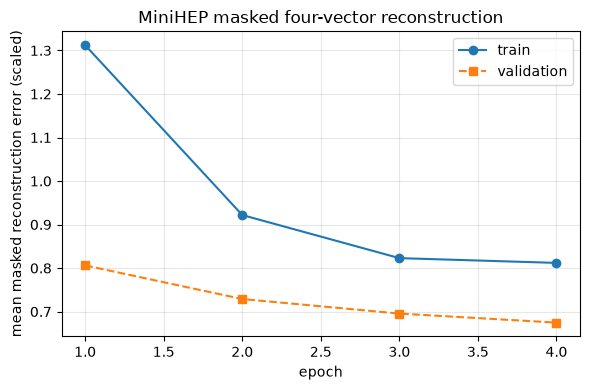

saved minihep_loss.png


In [6]:
# 6. Plot training and validation loss ------------------------------
epochs = np.arange(1, len(train_hist) + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs, train_hist, "o-", label="train")
plt.plot(epochs, val_hist, "s--", label="validation")
plt.xlabel("epoch")
plt.ylabel("mean masked reconstruction error (scaled)")
plt.title("MiniHEP masked four-vector reconstruction")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("minihep_loss.png", dpi=130)
plt.show()
print("saved minihep_loss.png")

## 7. Evaluate once on the held-out test split

The test split is used **once**, after model choices are settled.

In [7]:
# 7. Test split, once --------------------------------------------------
rng = np.random.default_rng(123)
test_mask = trn.mask_valid(Vte.numpy(), rng)
test_loss = trn.evaluate_recon(model, Xte, TTte, Vte, test_mask)
print(f"test masked reconstruction error: {test_loss:.4f} (in scaled components)")

test masked reconstruction error: 0.7090 (in scaled components)


/data/gwatts/minihep_student/train.py:153: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /home/conda/feedstock_root/build_artifacts/libtorch_1791515682889/work/torch/csrc/autograd/generated/python_variable_methods.cpp:822.)
  return float(masked_recon_loss(model, x, tt, valid, torch.from_numpy(mask)))


In [8]:
# 8. Event embeddings ---------------------------------------------------
emb = model.encode_events(Xte[:8], TTte[:8], Vte[:8])
print("eight event embeddings shape:", tuple(emb.shape))
print("first embedding:", [round(float(v), 3) for v in emb[0]])

eight event embeddings shape: (8, 32)
first embedding: [0.095, 0.321, -1.56, 0.6, -0.63, -0.167, 0.241, 0.772, 1.047, 0.161, 0.005, -0.384, 1.23, -0.279, -0.526, 0.894, 0.732, 0.008, -0.63, -0.25, 0.707, -0.675, -1.444, -1.53, -0.318, 0.557, -1.193, -0.284, 0.757, -0.214, 0.306, -0.359]


## Notes

- The plotted error is in **scaled four-vector components**; a falling curve is a useful software diagnostic but does not by itself show that the embedding is useful for H→WW classification.
- The `label`, event identity and MC weight are never token features.
- Absent jets are zero padding (the file's `-7` fillers are never used); MET is the transverse proxy `(MET cos φ, MET sin φ, 0, MET)`.